# 02 — Exploratory Data Analysis (EDA)

**Phase 2 / 3.** Pandas fundamentals applied to our dataset, followed by visual EDA.

Key questions addressed:
1. How many rows, products, and dates?
2. Are there missing values or data type inconsistencies?
3. What does the sales distribution look like across SKUs?
4. Does inventory availability constrain observed sales?
5. Which products experience the highest frequency of stockouts and censoring?

> **Note:** No model training is performed in this notebook.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Find root directory reliably
ROOT = next(
    p for p in (Path("."), Path(".."))
    if (p / "data" / "raw" / "observed_daily.csv").exists()
)

observed = pd.read_csv(ROOT / "data" / "raw" / "observed_daily.csv", parse_dates=["date"])
truth = pd.read_csv(ROOT / "data" / "raw" / "with_ground_truth.csv", parse_dates=["date"])

print(f"Observed shape : {observed.shape}")
print(f"Truth shape    : {truth.shape}")
print(f"Products ({observed['product'].nunique()}): {sorted(observed['product'].unique())}")
print(f"Date Range     : {observed['date'].min().date()} to {observed['date'].max().date()} ({observed['date'].nunique()} days)")

Observed shape : (1200, 12)
Truth shape    : (1200, 16)
Products (10): ['Biscuits', 'Bread', 'Eggs', 'Milk', 'Oil', 'Rice', 'Soap', 'Sugar', 'Tea', 'Yogurt']
Date Range     : 2025-09-01 to 2025-12-29 (120 days)


## 1. Schema, Types, and Missing Values

In [2]:
observed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1200 non-null   datetime64[ns]
 1   store          1200 non-null   object        
 2   product        1200 non-null   object        
 3   opening_stock  1200 non-null   int64         
 4   sales          1200 non-null   int64         
 5   closing_stock  1200 non-null   int64         
 6   price          1200 non-null   int64         
 7   promo          1200 non-null   int64         
 8   holiday        1200 non-null   int64         
 9   delivery_qty   1200 non-null   int64         
 10  stockout_flag  1200 non-null   int64         
 11  data_source    1200 non-null   object        
dtypes: datetime64[ns](1), int64(8), object(3)
memory usage: 112.6+ KB


In [3]:
observed.describe().round(2)

,date,opening_stock,sales,closing_stock,price,promo,holiday,delivery_qty,stockout_flag
count,1200,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,2025-10-30 12:00:00,20.69,9.32,11.37,63.70,0.06,0.02,9.18,0.27
min,2025-09-01 00:00:00,0.00,0.00,0.00,30.00,0.00,0.00,0.00,0.00
25%,2025-09-30 18:00:00,9.00,4.00,0.00,40.00,0.00,0.00,0.00,0.00
50%,2025-10-30 12:00:00,18.00,7.00,9.00,52.50,0.00,0.00,0.00,0.00
75%,2025-11-29 06:00:00,30.00,13.00,18.00,80.00,0.00,0.00,18.00,1.00
max,2025-12-29 00:00:00,67.00,52.00,51.00,140.00,1.00,1.00,50.00,1.00
std,NaN,15.62,7.95,11.38,31.61,0.25,0.16,15.62,0.44


In [4]:
print("Missing values per column:")
print(observed.isnull().sum())

Missing values per column:
date             0
store            0
product          0
opening_stock    0
sales            0
closing_stock    0
price            0
promo            0
holiday          0
delivery_qty     0
stockout_flag    0
data_source      0
dtype: int64


## 2. Sales Distribution Across SKUs

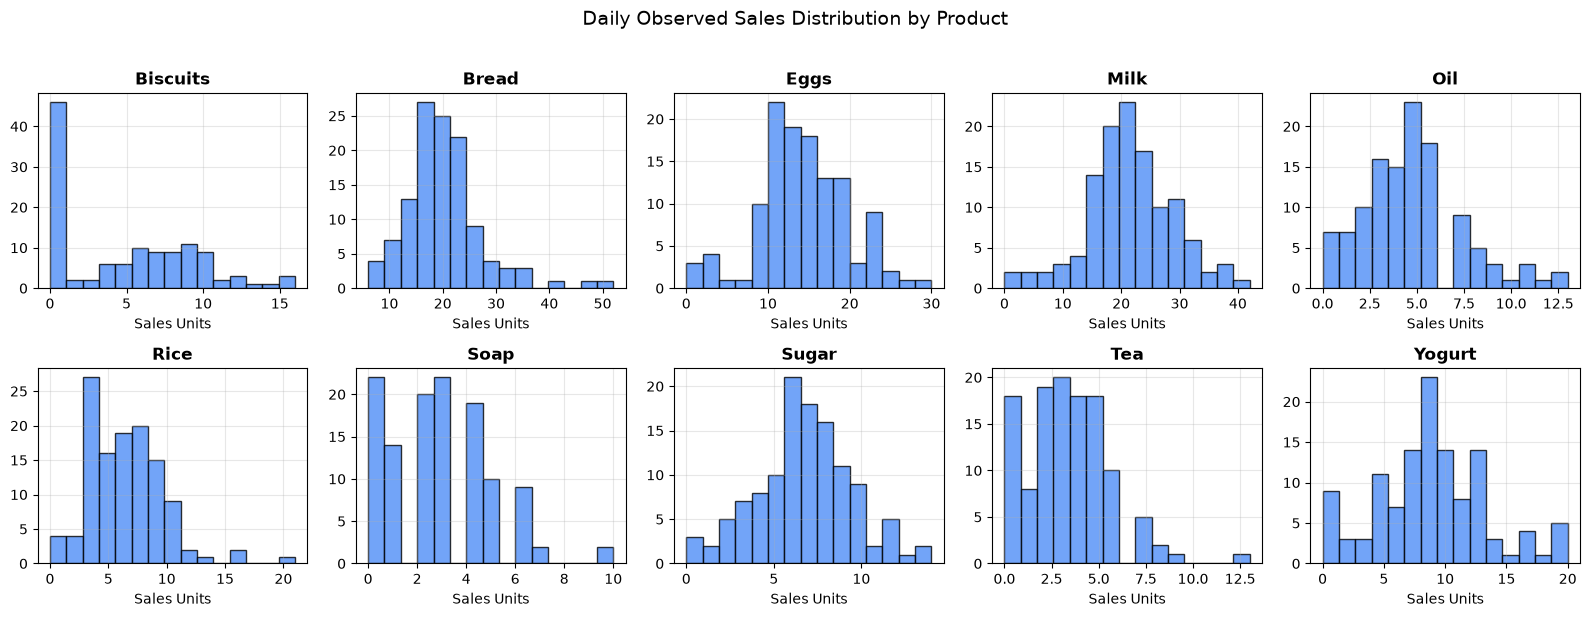

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=False)
axes = axes.flatten()

for i, prod in enumerate(sorted(observed["product"].unique())):
    subset = observed[observed["product"] == prod]
    axes[i].hist(subset["sales"], bins=15, color="#4f8ef7", edgecolor="black", alpha=0.8)
    axes[i].set_title(prod, fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Sales Units")
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Daily Observed Sales Distribution by Product", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. Daily Sales Over Time

Notice periods where sales flatline at 0 — this indicates stockout events.

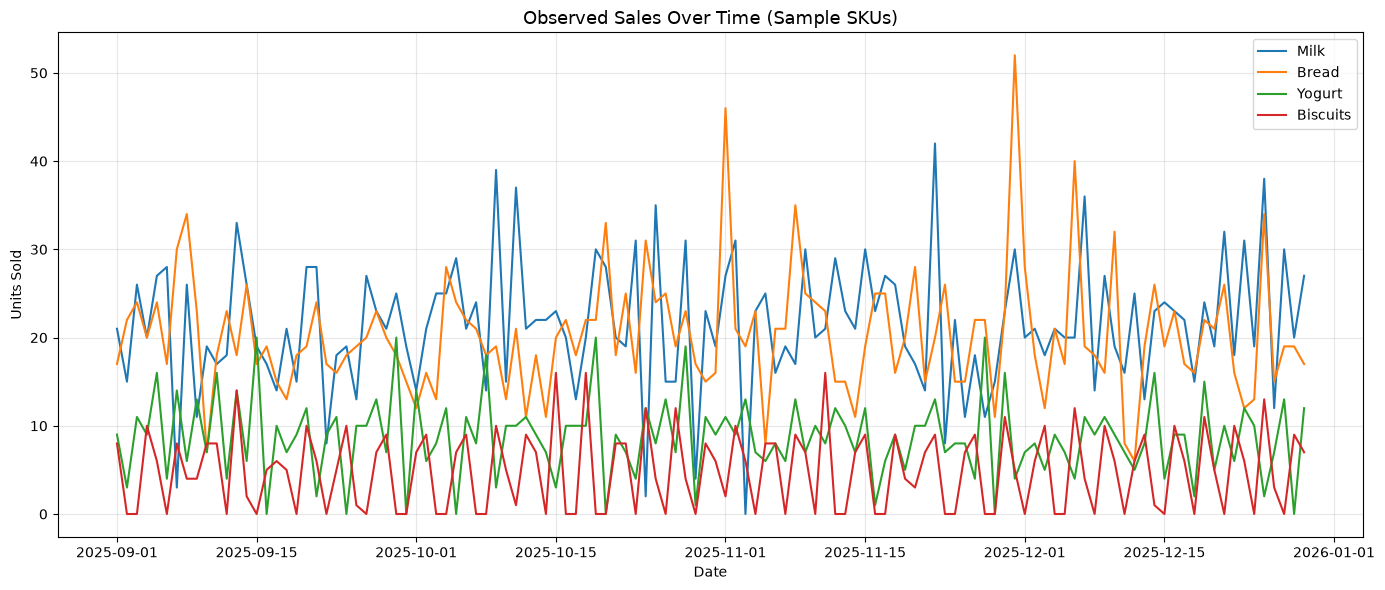

In [6]:
plt.figure(figsize=(14, 6))
for prod in ["Milk", "Bread", "Yogurt", "Biscuits"]:
    sub = observed[observed["product"] == prod].sort_values("date")
    plt.plot(sub["date"], sub["sales"], label=prod, linewidth=1.5)

plt.title("Observed Sales Over Time (Sample SKUs)", fontsize=13)
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Inventory vs Sales — Observing Censoring in Action

When available stock hits low levels, observed sales snap to available inventory. Customer demand exceeding stock is unrecorded.

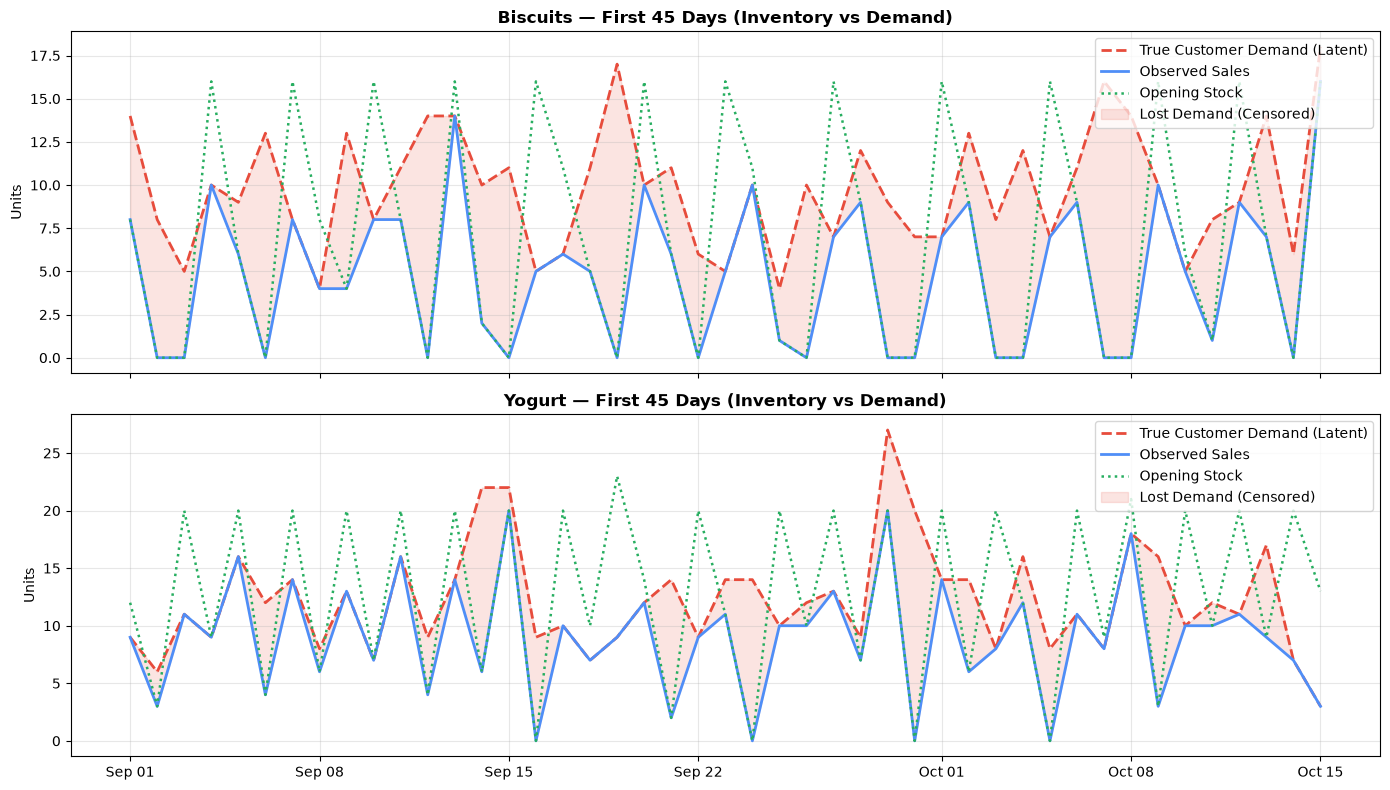

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for idx, prod in enumerate(["Biscuits", "Yogurt"]):
    sub_t = truth[truth["product"] == prod].sort_values("date").head(45)
    ax = axes[idx]
    ax.plot(sub_t["date"], sub_t["true_demand"], label="True Customer Demand (Latent)", color="#e74c3c", linestyle="--", linewidth=2)
    ax.plot(sub_t["date"], sub_t["sales"], label="Observed Sales", color="#4f8ef7", linewidth=2)
    ax.plot(sub_t["date"], sub_t["opening_stock"], label="Opening Stock", color="#27ae60", linestyle=":", linewidth=1.8)
    ax.fill_between(sub_t["date"], sub_t["sales"], sub_t["true_demand"], color="#e74c3c", alpha=0.15, label="Lost Demand (Censored)")
    ax.set_title(f"{prod} — First 45 Days (Inventory vs Demand)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Units")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

## 5. Stockout Frequency and Lost Sales by SKU

In [8]:
summary = (
    truth.groupby("product", as_index=False)
    .agg(
        days=("date", "count"),
        total_sales=("sales", "sum"),
        true_demand=("true_demand", "sum"),
        lost_sales=("lost_sales", "sum"),
        stockout_days=("stockout_flag", "sum"),
        censored_days=("is_censored", "sum"),
    )
)
summary["stockout_pct"] = (summary["stockout_days"] / summary["days"] * 100).round(1)
summary["censored_pct"] = (summary["censored_days"] / summary["days"] * 100).round(1)
summary = summary.sort_values("stockout_days", ascending=False).reset_index(drop=True)
summary

,product,days,total_sales,true_demand,lost_sales,stockout_days,censored_days,stockout_pct,censored_pct
0,Biscuits,120,584,1158,574,80,80,66.7,66.7
1,Yogurt,120,1044,1387,343,55,55,45.8,45.8
2,Tea,120,401,527,126,34,34,28.3,28.3
3,Milk,120,2567,3021,454,33,33,27.5,27.5
4,Soap,120,334,412,78,31,31,25.8,25.8
5,Eggs,120,1660,1893,233,30,30,25.0,25.0
6,Oil,120,569,648,79,23,23,19.2,19.2
7,Sugar,120,807,899,92,23,23,19.2,19.2
8,Rice,120,781,804,23,8,8,6.7,6.7
9,Bread,120,2437,2456,19,5,5,4.2,4.2


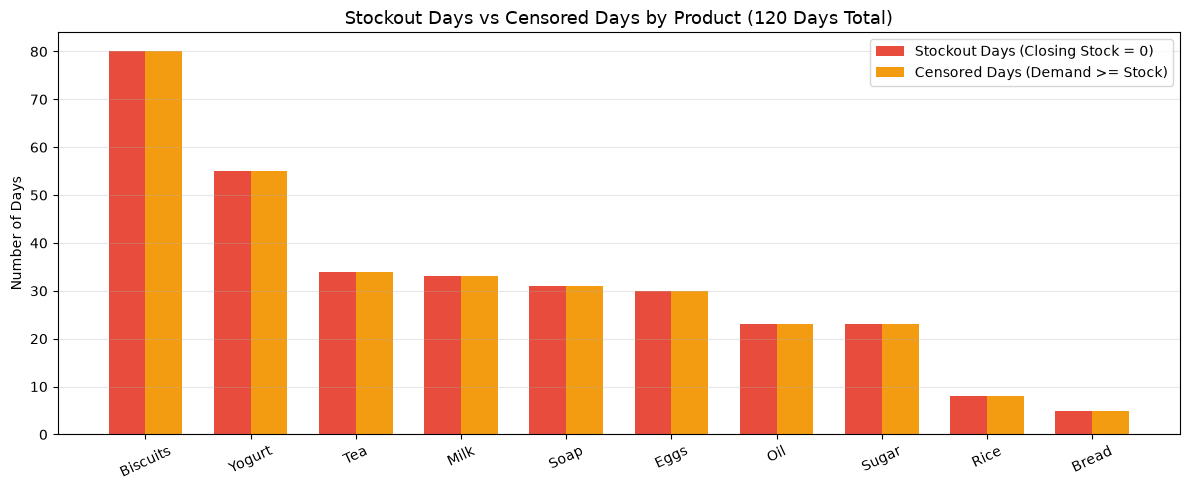

In [9]:
plt.figure(figsize=(12, 5))
x = np.arange(len(summary))
width = 0.35

plt.bar(x - width/2, summary["stockout_days"], width, label="Stockout Days (Closing Stock = 0)", color="#e74c3c")
plt.bar(x + width/2, summary["censored_days"], width, label="Censored Days (Demand >= Stock)", color="#f39c12")

plt.xticks(x, summary["product"], rotation=25)
plt.ylabel("Number of Days")
plt.title("Stockout Days vs Censored Days by Product (120 Days Total)", fontsize=13)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Summary of Findings

1. **Severe Censoring on Specific SKUs**: Products like `Biscuits` and `Yogurt` experience stockouts on 66.7% and 45.8% of days, respectively.
2. **Sales Diverges from Demand**: During stockout days, recorded sales drops to zero or is truncated at opening stock, creating artificial down-trends in historical logs.
3. **Zero Missing Values**: The data structure is complete with strict typing and no corrupt or negative entries.